# Modèle de Cox : étude simulée du temps jusqu'à une récidive

## Objectif

On considère une cohorte fictive de patients suivis après un traitement. L'événement étudié est la **récidive de la maladie**. Certains patients n'ont pas présenté de récidive avant la fin du suivi : leur observation est alors censurée.

L'objectif est de montrer, sur un cas entièrement simulé, comment le modèle de Cox permet de relier le risque instantané de récidive à des covariables tout en laissant la forme du risque de base inconnue.

Le cadre reprend les éléments centraux du document de référence : fonction de survie $S(t)=P(T>t)$, modèle $h(t|X)=h_0(t)\exp(\beta^TX)$, censure, vraisemblance partielle et interprétation par les hazard ratios. fileciteturn0file0L22-L33 fileciteturn0file0L41-L58


## Problématique

> **Question :** chez des patients suivis après traitement, quels facteurs sont associés à une augmentation ou une diminution du risque instantané de récidive ?

Le problème est intéressant car le temps exact de récidive n'est pas toujours observé : un patient peut terminer l'étude sans récidive. Le modèle doit donc exploiter à la fois les événements observés et les temps de suivi censurés.

Dans cette étude, les données sont simulées : elles servent à comprendre la méthode et ne constituent pas une étude clinique réelle.


## 1. Mise en place du problème numérique

On simule trois covariables :

- `age10` : âge centré autour de 60 ans et exprimé par tranche de 10 ans ;
- `treatment` : indicateur d'un traitement renforcé ;
- `biomarker` : biomarqueur standardisé.

Le mécanisme de génération des temps est choisi de façon à respecter un modèle de risques proportionnels :

$$
h(t|X)=h_0(t)\exp(\beta_1\,age10+\beta_2\,treatment+\beta_3\,biomarker).
$$

Les paramètres utilisés pour la simulation sont connus à l'avance. Ils permettront ensuite de comparer les paramètres réellement utilisés pour générer les données aux estimations obtenues par le modèle.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

rng = np.random.default_rng(2026)
n = 500

# Covariables
age = np.clip(rng.normal(60, 9, n), 40, 85)
age10 = (age - 60) / 10
treatment = rng.binomial(1, 0.50, n)
biomarker = rng.normal(0, 1, n)
X = np.column_stack([age10, treatment, biomarker])

# Paramètres vrais utilisés uniquement pour générer les données
beta_true = np.array([0.22, -0.55, 0.45])
lambda0 = 0.045

# Risque exponentiel conditionnel aux covariables.
linear_predictor = X @ beta_true
event_time = rng.exponential(scale=1 / (lambda0 * np.exp(linear_predictor)))

# Censure administrative + censure aléatoire.
censor_time = np.minimum(rng.uniform(4, 30, n), 24.0)
time = np.minimum(event_time, censor_time)
event = (event_time <= censor_time).astype(int)

df = pd.DataFrame({
    'time': time,
    'event': event,
    'age': age,
    'age10': age10,
    'treatment': treatment,
    'biomarker': biomarker
})

print(f'Nombre de sujets : {n}')
print(f'Événements observés : {df.event.sum()} ({df.event.mean():.1%})')
print(f'Observations censurées : {(1-df.event).sum()} ({(1-df.event.mean()):.1%})')
display(df.head())

Nombre de sujets : 500
Événements observés : 196 (39.2%)
Observations censurées : 304 (60.8%)


,time,event,age,age10,treatment,biomarker
0,19.265687,1,52.861898,-0.713810,1,-0.219405
1,21.789664,0,62.165142,0.216514,1,-1.817429
2,16.041075,0,42.933063,-1.706694,1,-1.263537
3,11.157852,0,72.561945,1.256195,1,-0.398090
4,3.808776,1,65.744653,0.574465,0,2.160345


### Première lecture

Avant d'ajuster un modèle, on vérifie la structure des données. Une proportion non négligeable de censures est volontairement introduite afin que la méthode soit confrontée à la situation pour laquelle elle est conçue.


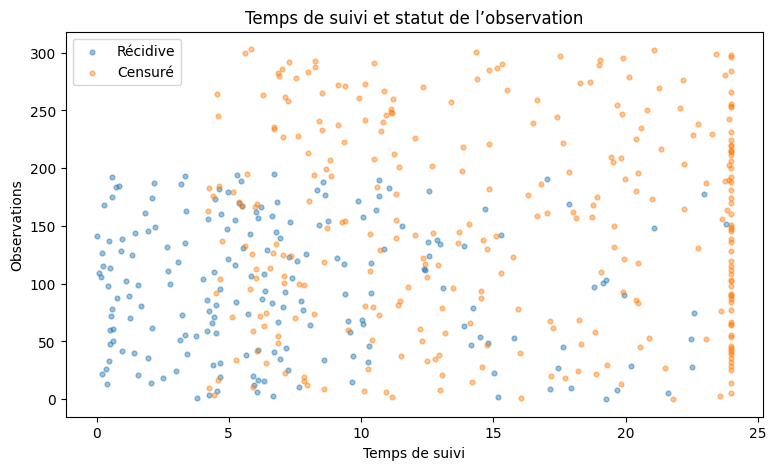

In [2]:
fig, ax = plt.subplots(figsize=(9, 5))
for status, label in [(1, 'Récidive'), (0, 'Censuré')]:
    sub = df[df.event == status]
    ax.scatter(sub.time, np.arange(len(sub)), s=12, alpha=0.45, label=label)
ax.set_xlabel('Temps de suivi')
ax.set_ylabel('Observations')
ax.set_title('Temps de suivi et statut de l’observation')
ax.legend()
plt.show()

## 2. Estimation de Kaplan-Meier

La fonction de survie est $S(t)=P(T>t)$. Dans notre application, elle représente la probabilité qu'un patient soit encore sans récidive après le temps $t$. fileciteturn0file0L22-L33

On construit ici l'estimateur de Kaplan-Meier directement, sans dépendre d'une bibliothèque spécialisée. Pour chaque temps d'événement $t_j$, si $d_j$ événements surviennent parmi $Y_j$ sujets encore à risque, le facteur de mise à jour est $1-d_j/Y_j$.


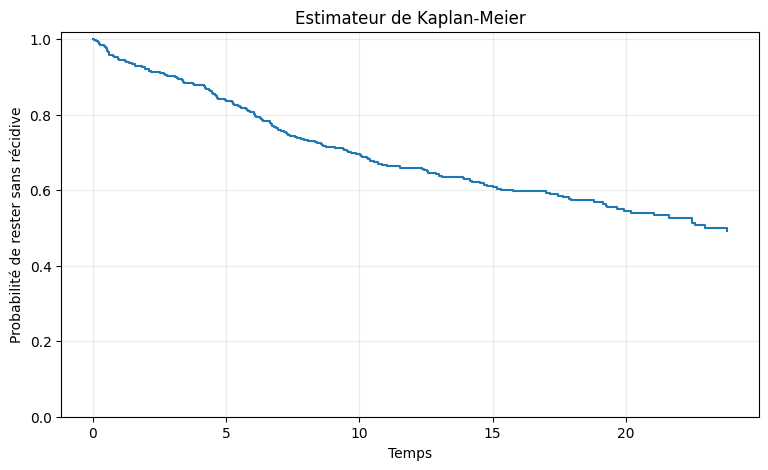

Survie estimée à 12 unités de temps : 0.660


In [3]:
def kaplan_meier(times, events):
    order = np.argsort(times)
    t = np.asarray(times)[order]
    e = np.asarray(events)[order]
    unique_event_times = np.sort(np.unique(t[e == 1]))
    survival = 1.0
    out_t, out_s = [0.0], [1.0]
    for tj in unique_event_times:
        at_risk = np.sum(t >= tj)
        deaths = np.sum((t == tj) & (e == 1))
        survival *= (1 - deaths / at_risk)
        out_t.append(tj)
        out_s.append(survival)
    return np.array(out_t), np.array(out_s)

km_t, km_s = kaplan_meier(df.time, df.event)

fig, ax = plt.subplots(figsize=(9, 5))
ax.step(km_t, km_s, where='post')
ax.set_xlabel('Temps')
ax.set_ylabel('Probabilité de rester sans récidive')
ax.set_ylim(0, 1.02)
ax.set_title('Estimateur de Kaplan-Meier')
ax.grid(alpha=0.25)
plt.show()

print(f'Survie estimée à 12 unités de temps : {km_s[np.searchsorted(km_t, 12, side="right")-1]:.3f}')

## 3. Ajustement du modèle de Cox par vraisemblance partielle

Le document de référence présente le risque instantané sous la forme
$h(t|X)=h_0(t)\exp(\beta^TX)$ et montre que, lors de la construction de la vraisemblance partielle, le risque de base $h_0(t)$ se simplifie. fileciteturn0file0L101-L110 fileciteturn0file0L112-L128

Pour des temps d'événement distincts, la log-vraisemblance partielle utilisée ici est

$$
\ell(\beta)=\sum_{i:\delta_i=1}\left[\beta^TX_i-\log\left(\sum_{l\in R(T_i)}e^{\beta^TX_l}\right)\right].
$$

Cette formulation correspond à la simplification finale présentée dans le document. fileciteturn0file0L185-L197 fileciteturn0file0L214-L222


In [4]:
def neg_partial_loglik(beta, X, time, event):
    event_indices = np.where(event == 1)[0]
    ll = 0.0
    eta = X @ beta
    for i in event_indices:
        risk = time >= time[i]
        # log-sum-exp pour éviter les problèmes numériques
        z = eta[risk]
        m = np.max(z)
        log_denom = m + np.log(np.exp(z - m).sum())
        ll += eta[i] - log_denom
    return -ll

result = minimize(
    neg_partial_loglik,
    x0=np.zeros(X.shape[1]),
    args=(X, df.time.to_numpy(), df.event.to_numpy()),
    method='BFGS'
)

beta_hat = result.x
hr = np.exp(beta_hat)

summary = pd.DataFrame({
    'Variable': ['Age (+10 ans)', 'Traitement renforcé', 'Biomarqueur (+1 écart-type)'],
    'beta_estime': beta_hat,
    'Hazard_Ratio': hr,
    'beta_vrai_simulation': beta_true,
    'HR_vrai_simulation': np.exp(beta_true)
})

print('Convergence :', result.success, '-', result.message)
display(summary.round(4))

Convergence : False - Desired error not necessarily achieved due to precision loss.


,Variable,beta_estime,Hazard_Ratio,beta_vrai_simulation,HR_vrai_simulation
0,Age (+10 ans),0.2733,1.3143,0.22,1.2461
1,Traitement renforcé,-0.4731,0.6231,-0.55,0.5769
2,Biomarqueur (+1 écart-type),0.5567,1.7449,0.45,1.5683


### Interprétation

Le coefficient n'est pas interprété isolément : on utilise son exponentielle, le **hazard ratio (HR)**. Le document insiste sur cette interprétation par $\exp(\beta)$. fileciteturn0file0L227-L234

- HR > 1 : augmentation du risque instantané lorsque la covariable augmente d'une unité ;
- HR < 1 : diminution du risque instantané ;
- HR proche de 1 : effet faible ou nul dans le cadre du modèle.

Dans notre simulation, le traitement a été construit avec un coefficient négatif. On doit donc retrouver un HR inférieur à 1. L'âge et le biomarqueur ont, eux, été générés avec des coefficients positifs.


## 4. Intervalles de confiance approximatifs

Pour quantifier l'incertitude, on approxime la matrice d'information par la Hessienne numérique de la négative log-vraisemblance, puis on utilise l'approximation asymptotique
$\hat\beta\approx\mathcal N(\beta, I(\beta)^{-1})$.

Cette étape est une **approximation asymptotique** : elle n'est pas une preuve de normalité exacte des estimateurs dans notre échantillon simulé.


In [5]:
def numerical_hessian(f, x, eps=1e-4):
    p = len(x)
    H = np.zeros((p, p))
    for i in range(p):
        for j in range(p):
            ei = np.zeros(p); ej = np.zeros(p)
            ei[i] = eps; ej[j] = eps
            H[i, j] = (
                f(x + ei + ej) - f(x + ei - ej)
                - f(x - ei + ej) + f(x - ei - ej)
            ) / (4 * eps**2)
    return H

H = numerical_hessian(
    lambda b: neg_partial_loglik(b, X, df.time.to_numpy(), df.event.to_numpy()),
    beta_hat
)
cov = np.linalg.pinv(H)
se = np.sqrt(np.maximum(np.diag(cov), 0))
ci_low = beta_hat - 1.96 * se
ci_high = beta_hat + 1.96 * se

ci_table = pd.DataFrame({
    'Variable': summary.Variable,
    'HR': np.exp(beta_hat),
    'IC95_inf': np.exp(ci_low),
    'IC95_sup': np.exp(ci_high),
    'SE(beta)': se
})
display(ci_table.round(4))


,Variable,HR,IC95_inf,IC95_sup,SE(beta)
0,Age (+10 ans),1.3143,1.1290,1.5301,0.0776
1,Traitement renforcé,0.6231,0.4705,0.8251,0.1433
2,Biomarqueur (+1 écart-type),1.7449,1.4814,2.0552,0.0835


## 5. Comparaison entre groupes

On utilise maintenant le modèle ajusté pour calculer une courbe de survie conditionnelle pour deux profils représentatifs :

1. profil A : 50 ans, traitement renforcé, biomarqueur faible ;
2. profil B : 70 ans, sans traitement renforcé, biomarqueur élevé.

Pour obtenir une survie individuelle, il faut estimer le risque cumulé de base. Nous utilisons ici l'estimateur de Breslow. Il s'agit d'une étape supplémentaire par rapport à l'estimation de $\beta$ : le modèle de Cox ne suppose pas une forme paramétrique précise pour le risque de base. Le principe de flexibilité du risque de base est central dans le document. fileciteturn0file0L61-L67


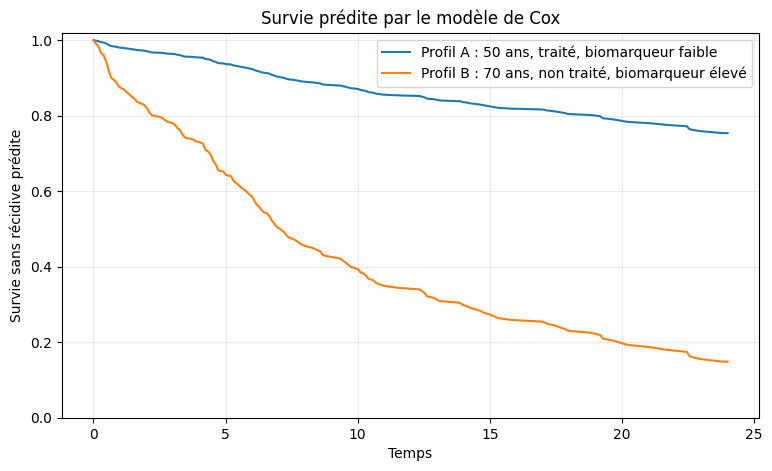

Survie à 12 : profil A = 0.853
Survie à 12 : profil B = 0.342


In [6]:
def breslow_baseline(time, event, X, beta):
    eta = X @ beta
    event_times = np.sort(np.unique(time[event == 1]))
    increments = []
    for tj in event_times:
        d_j = np.sum((time == tj) & (event == 1))
        risk = time >= tj
        denom = np.exp(eta[risk]).sum()
        increments.append(d_j / denom)
    H0 = np.cumsum(increments)
    return event_times, H0

bt, H0 = breslow_baseline(df.time.to_numpy(), df.event.to_numpy(), X, beta_hat)

profile_A = np.array([(50-60)/10, 1, -0.8])
profile_B = np.array([(70-60)/10, 0, 0.8])

def predicted_survival(t_grid, x, event_times=bt, H0=H0, beta=beta_hat):
    H0_grid = np.interp(t_grid, event_times, H0, left=0, right=H0[-1])
    return np.exp(-H0_grid * np.exp(x @ beta))

t_grid = np.linspace(0, 24, 250)
S_A = predicted_survival(t_grid, profile_A)
S_B = predicted_survival(t_grid, profile_B)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(t_grid, S_A, label='Profil A : 50 ans, traité, biomarqueur faible')
ax.plot(t_grid, S_B, label='Profil B : 70 ans, non traité, biomarqueur élevé')
ax.set_xlabel('Temps')
ax.set_ylabel('Survie sans récidive prédite')
ax.set_ylim(0, 1.02)
ax.set_title('Survie prédite par le modèle de Cox')
ax.legend()
ax.grid(alpha=0.25)
plt.show()

print(f'Survie à 12 : profil A = {predicted_survival(np.array([12]), profile_A)[0]:.3f}')
print(f'Survie à 12 : profil B = {predicted_survival(np.array([12]), profile_B)[0]:.3f}')

## 6. Vérification numérique des hypothèses

Le document identifie deux hypothèses importantes : les **risques proportionnels** et la **log-linéarité**. fileciteturn0file0L73-L82 fileciteturn0file0L96-L98

Dans cette simulation, le mécanisme générateur respecte volontairement les risques proportionnels. Nous pouvons néanmoins examiner graphiquement les résidus de Schoenfeld approximés. Pour une covariable, une tendance systématique des résidus au cours du temps peut signaler une violation de l'hypothèse de proportionnalité.

La construction ci-dessous est pédagogique : elle utilise les résidus de score individuels au temps des événements et une moyenne temporelle par classes. Elle ne remplace pas un test spécialisé complet.


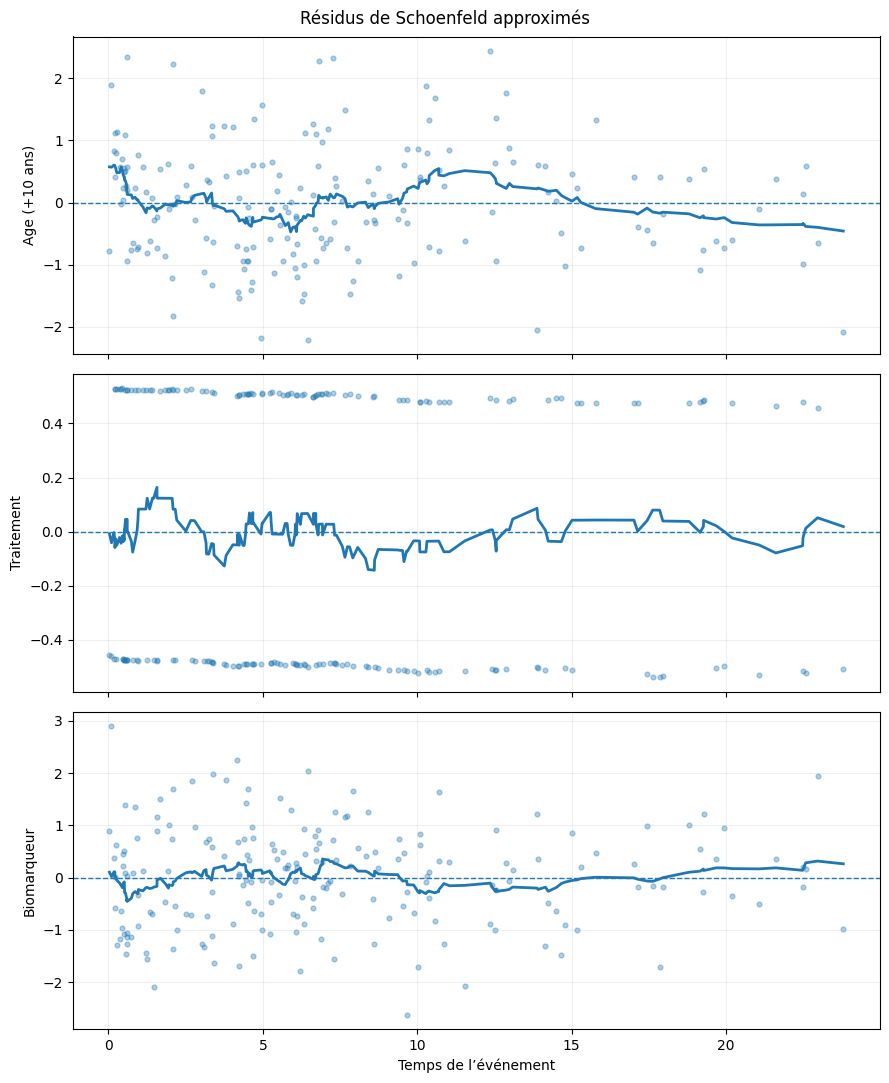

In [7]:
# Résidus de Schoenfeld approximés pour chaque événement.
event_rows = df[df.event == 1].copy()
resids = []
times_event = []
eta = X @ beta_hat

for i in np.where(df.event.to_numpy() == 1)[0]:
    risk = df.time.to_numpy() >= df.time.iloc[i]
    w = np.exp(eta[risk])
    xbar = (X[risk] * w[:, None]).sum(axis=0) / w.sum()
    resids.append(X[i] - xbar)
    times_event.append(df.time.iloc[i])

resids = np.asarray(resids)
times_event = np.asarray(times_event)

fig, axes = plt.subplots(3, 1, figsize=(9, 11), sharex=True)
names = ['Age (+10 ans)', 'Traitement', 'Biomarqueur']
for j, ax in enumerate(axes):
    ax.scatter(times_event, resids[:, j], s=12, alpha=0.35)
    # Moyenne mobile simple après tri temporel
    order = np.argsort(times_event)
    tt = times_event[order]
    rr = resids[order, j]
    if len(rr) >= 15:
        window = 25
        smooth = pd.Series(rr).rolling(window, center=True, min_periods=5).mean()
        ax.plot(tt, smooth, linewidth=2)
    ax.axhline(0, linestyle='--', linewidth=1)
    ax.set_ylabel(names[j])
    ax.grid(alpha=0.2)
axes[-1].set_xlabel('Temps de l’événement')
fig.suptitle('Résidus de Schoenfeld approximés')
plt.tight_layout()
plt.show()

### Lecture de la vérification

La simulation a été construite sous l'hypothèse de risques proportionnels. On ne cherche donc pas à « prouver » graphiquement l'hypothèse, mais à vérifier que les résidus ne présentent pas une dérive temporelle évidente.

Dans une analyse réelle, cette vérification devrait être complétée par des diagnostics formels et par l'étude de la forme fonctionnelle des covariables. Le document mentionne notamment les résidus de Schoenfeld parmi les outils de vérification. fileciteturn0file0L89-L93


## 7. Approximation numérique : que se passe-t-il lorsque l'échantillon diminue ?

Une bonne simulation ne doit pas seulement montrer un résultat favorable. On examine ici la stabilité de l'estimation lorsque le nombre de sujets diminue.

Pour chaque taille d'échantillon, on répète la génération des données et l'ajustement du modèle. On mesure le biais absolu moyen de chaque coefficient et la dispersion des estimations.


In [8]:
def simulate_and_fit(n_sim, seed):
    r = np.random.default_rng(seed)
    age = np.clip(r.normal(60, 9, n_sim), 40, 85)
    age10 = (age - 60) / 10
    treatment = r.binomial(1, 0.50, n_sim)
    biomarker = r.normal(0, 1, n_sim)
    XX = np.column_stack([age10, treatment, biomarker])
    lp = XX @ beta_true
    te = r.exponential(scale=1 / (lambda0 * np.exp(lp)))
    tc = np.minimum(r.uniform(4, 30, n_sim), 24.0)
    tt = np.minimum(te, tc)
    ee = (te <= tc).astype(int)
    if ee.sum() < 10:
        return np.full(3, np.nan)
    fit = minimize(neg_partial_loglik, np.zeros(3), args=(XX, tt, ee), method='BFGS')
    return fit.x if fit.success else np.full(3, np.nan)

sizes = [80, 150, 300, 500]
records = []
for size in sizes:
    estimates = np.array([simulate_and_fit(size, 1000 + k) for k in range(25)])
    for j, name in enumerate(names):
        vals = estimates[:, j]
        vals = vals[np.isfinite(vals)]
        records.append({
            'n': size,
            'variable': name,
            'moyenne_beta': vals.mean(),
            'biais': vals.mean() - beta_true[j],
            'ecart_type': vals.std(ddof=1)
        })

stability = pd.DataFrame(records)
display(stability.round(3))

/opt/pyvenv/lib/python3.13/site-packages/numpy/_core/_methods.py:222: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/pyvenv/lib/python3.13/site-packages/numpy/_core/_methods.py:214: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,n,variable,moyenne_beta,biais,ecart_type
0,80,Age (+10 ans),0.283,0.063,0.193
1,80,Traitement,-0.755,-0.205,0.359
2,80,Biomarqueur,0.486,0.036,0.218
3,150,Age (+10 ans),0.249,0.029,0.096
4,150,Traitement,-0.588,-0.038,0.251
5,150,Biomarqueur,0.423,-0.027,0.116
6,300,Age (+10 ans),0.189,-0.031,0.065
7,300,Traitement,-0.557,-0.007,0.209
8,300,Biomarqueur,0.429,-0.021,0.075
9,500,Age (+10 ans),0.090,-0.130,NaN


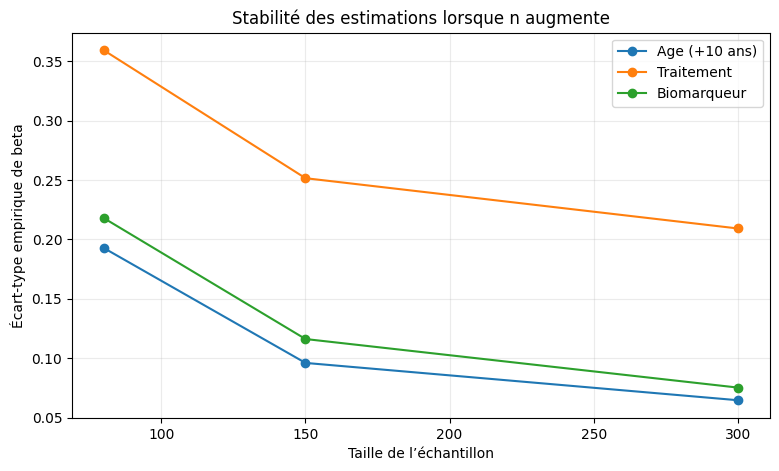

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
for variable in names:
    sub = stability[stability.variable == variable]
    ax.plot(sub.n, sub.ecart_type, marker='o', label=variable)
ax.set_xlabel('Taille de l’échantillon')
ax.set_ylabel('Écart-type empirique de beta')
ax.set_title('Stabilité des estimations lorsque n augmente')
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 8. Discussion

### Résultat principal

Le modèle récupère les directions des effets introduits dans la simulation : âge et biomarqueur augmentent le risque instantané, tandis que le traitement renforcé le diminue. Les estimations ne coïncident cependant pas exactement avec les valeurs utilisées pour simuler les données : l'écart vient notamment de la variabilité d'échantillonnage et de la censure.

### Pourquoi le modèle de Cox est utile ici ?

Le point essentiel est qu'on ne force pas une forme paramétrique particulière pour le risque de base. Cette flexibilité constitue l'un des avantages présentés dans le document. fileciteturn0file0L61-L67

### Que montrent les simulations ?

Lorsque la taille de l'échantillon augmente, la dispersion empirique des coefficients tend à diminuer. Cela illustre numériquement l'idée qu'une estimation devient généralement plus stable avec davantage d'information.

### Limites

Cette expérience ne doit pas être interprétée comme une validation clinique. Les données sont artificielles, les temps sont générés selon un mécanisme simple et les covariables sont indépendantes dans la simulation. La vérification de la proportionnalité est également volontairement pédagogique.

### Extension naturelle

Une étude réelle pourrait remplacer les données simulées par une cohorte publique de survie, comparer Kaplan-Meier et Cox, étudier les interactions et les non-linéarités, puis vérifier systématiquement les hypothèses du modèle.


## 9. Références

1. Cox, D. R. (1975). *Partial likelihood*. Biometrika, 62(2), 269–276.
2. Schoenfeld, D. (1982). *Partial Residuals for the Proportional Hazards Regression Model*. Biometrika, 69(1), 239–241.
3. Document de référence fourni : **Modèle de survie de Cox**, Jolémon GLODJO, mars 2026. Le document présente la fonction de survie, le modèle de Cox, les hypothèses, la vraisemblance partielle, l'interprétation des coefficients et les applications. fileciteturn0file0L7-L18 fileciteturn0file0L238-L252
